In [1]:
!pip install -q h5py

In [2]:
path="/content/drive/MyDrive/2026B/TestTeachebleMachine/"

In [3]:
import tf_keras as legacy_keras

# Carga y guarda usando el Keras antiguo
model = legacy_keras.models.load_model(path+'keras_model.h5')

# Nota: Guardarlo aquí como .keras seguirá el estándar antiguo de tf_keras
model.save(path+'keras_model.keras')


In [4]:
import tensorflow as tf
import numpy as np
import tf_keras as legacy_keras # Import tf_keras for consistent loading
import matplotlib.pyplot as plt

# 1. Cargar el modelo final (sin necesidad de compilar)
# Use legacy_keras to load the model, consistent with how it was saved
model = legacy_keras.models.load_model(path+'keras_model.keras')

# 2. Preparar tus nuevos datos (asegúrate de que tengan el mismo formato y escala)
# Ejemplo con datos aleatorios que simulan tus entradas:
datos_entrada = np.random.rand(1, 224, 224, 3)

# 3. Hacer la predicción
predicciones = model.predict(datos_entrada)

print(predicciones)

1/1 [==============================] - 3s 3s/step
[[1.8580946e-04 6.7498686e-04 5.2792722e-05 1.8718947e-06 6.5668537e-03
  2.0795532e-02 1.4192692e-03 2.4610429e-04 3.2955769e-03 9.3279535e-01
  6.1712414e-03 2.6893738e-04 1.7718073e-02 3.4261617e-04 1.0239081e-03
  1.4708430e-04 8.2940487e-03]]


In [5]:
#import sys
#!{sys.executable} -m pip install tensorflow==2.20.0

In [6]:
import tf_keras as legacy_keras
import cv2
import numpy as np
from google.colab.output import eval_js
from IPython.display import display, Javascript
from base64 import b64decode

# 1. Configuración inicial del modelo
np.set_printoptions(suppress=True)
model = legacy_keras.models.load_model(path + "keras_model.keras", compile=False)
class_names = open(path + "labels.txt", "r").readlines()

# 2. Función en JavaScript para activar y capturar la cámara web
def start_webcam():
  js = Javascript('''
    async function startWebcam() {
      const div = document.createElement('div');
      const video = document.createElement('video');
      video.style.display = 'block';
      const stream = await navigator.mediaDevices.getUserMedia({video: true});

      // Crear un botón para detener la captura si se desea
      const button = document.createElement('button');
      button.textContent = 'Detener Cámara';
      div.appendChild(video);
      div.appendChild(button);
      document.body.appendChild(div);

      video.srcObject = stream;
      await video.play();

      // Ajustar el tamaño del stream visible
      google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);



      // Promesa para capturar fotogramas continuamente

    // Capturar imagen de 265 x 265
    window.captureFrame = function() {

        const canvas = document.createElement('canvas');

        // Tamaño EXACTO de salida
        const targetSize = 265;

        canvas.width = targetSize;
        canvas.height = targetSize;

        const ctx = canvas.getContext('2d');

        // Dimensiones reales de la cámara
        const videoWidth = video.videoWidth;
        const videoHeight = video.videoHeight;

        // Tomar el menor tamaño para crear un recorte cuadrado
        const size = Math.min(videoWidth, videoHeight);

        // Centrar el recorte
        const sx = (videoWidth - size) / 2;
        const sy = (videoHeight - size) / 2;

        // Dibujar y redimensionar a 265 x 265
        ctx.drawImage(
            video,
            sx,
            sy,
            size,
            size,
            0,
            0,
            targetSize,
            targetSize
        );

        // Retornar imagen JPEG
        return canvas.toDataURL('image/jpeg', 0.8);
    };

      return new Promise((resolve) => {
        button.onclick = () => {
          //stream.getTracks().forEach(track => track.stop());
          //div.remove();
          resolve('Camara detenida');
        };
      });
    }
    ''')
  display(js)
  eval_js('startWebcam()')


In [7]:
# 3. Función para convertir la imagen de JS a formato OpenCV (NumPy)
def js_to_image(js_reply):
  image_bytes = b64decode(js_reply.split(',')[1])
  image_as_np = np.frombuffer(image_bytes, dtype=np.uint8)
  img = cv2.imdecode(image_as_np, flags=cv2.IMREAD_COLOR)
  return img

<IPython.core.display.Javascript object>

Procesando stream de video...

Original image
shape (265, 265, 3) max intensity 216

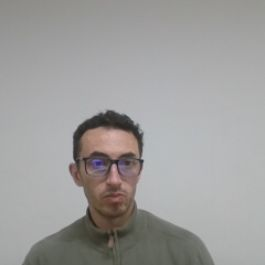

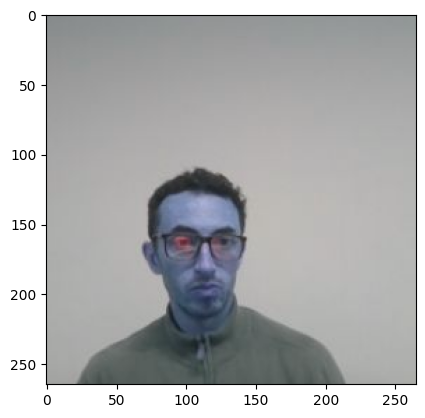

Reshape
shape (224, 224, 3) max intensity 215


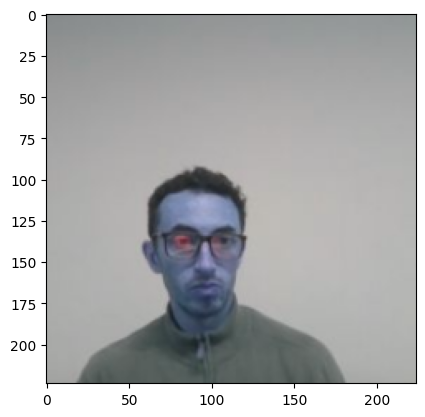

Reshape 2
shape (1, 224, 224, 3) max intensity 215.0


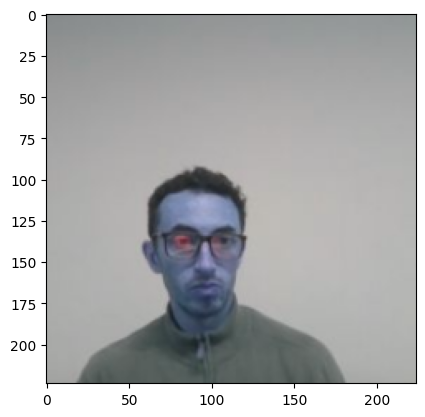

Normalize
shape (1, 224, 224, 3) max intensity 0.6862745


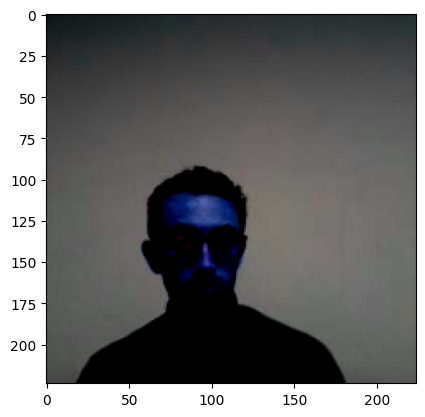

1/1 [==============================] - 1s 741ms/step
Prediction [[0.05676385 0.00047876 0.00000378 0.00000475 0.00004973 0.00436288
  0.04960716 0.00027894 0.03138514 0.84179604 0.00000317 0.00000594
  0.00006857 0.00002631 0.00667525 0.00380274 0.00468697]]
Class: Cortes
Confidence Score: 84 %
Bucle finalizado o error: OpenCV(5.0.0) /io/opencv/modules/highgui/src/window.cpp:1262: error: (-2:Unspecified error) The function is not implemented. Rebuild the library with Windows, GTK+ 2.x or Cocoa support. If you are on Ubuntu or Debian, install libgtk2.0-dev and pkg-config, then re-run cmake or configure script in function 'waitKeyImpl'



In [9]:
start_webcam()
#eval_js('captureFrame()')
print("Procesando stream de video...")
while True:
    try:
        # Captura el fotograma actual desde el navegador de manera asíncrona
        js_image = eval_js('captureFrame()')
        print(js_image)
        if not js_image:
            break

        # Reemplazo de cv2.VideoCapture: Convertimos el fotograma a formato OpenCV
        image = js_to_image(js_image)
        print("Original image")
        print("shape", image.shape, "max intensity", np.max(image))
        plt.imshow(image)
        plt.show()
        # Redimensionar la imagen para tu modelo Teachable Machine / Keras
        image = cv2.resize(image, (224, 224), interpolation=cv2.INTER_AREA)
        b,g,r=cv2.split(image)
        image=cv2.merge((r,g,b))
        print("Reshape")
        print("shape", image.shape, "max intensity", np.max(image))
        plt.imshow(image)
        plt.show()
        # Make the image a numpy array and reshape it to the models input shape.
        image = np.asarray(image, dtype=np.float32).reshape(1, 224, 224, 3)
        print("Reshape 2")
        print("shape", image.shape, "max intensity", np.max(image))
        plt.imshow(np.int32(image[0]))
        plt.show()
        # Normalize the image array
        image = (image / 127.5) - 1
        print("Normalize")
        print("shape", image.shape, "max intensity", np.max(image))
        plt.imshow(image[0])
        plt.show()

        # Predicts the model
        prediction = model.predict(image)
        index = np.argmax(prediction)
        class_name = class_names[index]
        confidence_score = prediction[0][index]

        # Print prediction and confidence score
        print("Prediction",prediction)
        print("Class:", class_name[2:], end="")
        print("Confidence Score:", str(np.round(confidence_score * 100))[:-2], "%")

        # Listen to the keyboard for presses.
        keyboard_input = cv2.waitKey(1)

        # 27 is the ASCII for the esc key on your keyboard.
        if keyboard_input == 27:
            break


    except Exception as err:
        # Esto detiene el bucle limpiamente si cierras la ventana de la cámara
        print(f"Bucle finalizado o error: {err}")
        break



In [ ]:
image.shape

In [ ]:
image[0].shape
plt.imshow(image[0])